In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interactive_output, HBox, VBox, Layout, fixed



    

def examineChannelNormal(channel,ax=None,nSamples = 51):
    if ax is None:
        fig,ax = plt.subplots(3,3,figsize=(12,8), dpi=80)
        fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    gateOpening = np.ones([nSamples])
    for i,(gate,gateData) in enumerate(channel["gates"].items()):
        if gate != "spikeGate":
            if gate == "CaGate":
                vr = np.linspace(0,1e-3,nSamples)
                xInf = examineGateNormal(gateData,vr,gate,[ax[0,i],ax[1,i]])
            else:
                valRange = np.linspace(-100,100,nSamples)
                xInf = examineGateNormal(gateData,valRange,gate,[ax[0,i],ax[1,i]])
                exponent = gateData["exponent"]
                gateOpening *= xInf**exponent

    ax[2,0].plot(valRange,gateOpening,c="orange",ls="--")
    plt.tight_layout()


    
def genGate(vHalf,vKi,tau0,tau1,th,tkInv,x0=0.0,exponent=1,minOpenness=0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,"th":th,"tkInv":tkInv,"exponent":exponent,"minOpenness":minOpenness}

def genOpenGate():
    return genGate(-1000,1000,100,1000,0,0,x0=1)

def genSynapseGate(xt1,TS):
    xt0 = TS
    xt1 = xt1-xt0
    return genGate(0.5,100,xt0,xt1,0.5,-100)

def sigmoid(z,h,kInv,minOp):
    return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))

def examineGateNormal(gateData,valRange,gateName,ax=None):
    xInf = sigmoid(valRange,gateData["vHalf"],gateData["vKi"],gateData["minOpenness"]) 
    xTau = gateData["tau0"] + gateData["tau1"]*sigmoid(valRange,gateData["th"],gateData["tkInv"],0)
    gRange = [min(valRange),max(valRange)]

    if ax is None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    
    ax[0].plot(valRange,xInf,c="b",ls="--")
    ax[0].axvline(gateData["vHalf"],color="g",linestyle="--")
    ax[0].set_title(f"{gateName} xInf")
    ax[0].set_xlim(gRange)
    #x[0].set_ylabel("Gate opening")
    ax[0].set_ylim(-0.01,1.01)

    ax[1].plot(valRange,xTau,c="b",ls="--")
    ax[1].axvline(gateData["th"],color="g",linestyle="--")
    ax[1].set_title(f"{gateName} tau")
    #ax[1].set_ylabel("Time constant (ms)")
    ax[1].set_xlim(gRange)
    
    return xInf

# --- Interactive Plotter Bridge ---
# This was done with Gemini
def update_plot(vHalf, vK, tau0, tau1, th, tk,w_exp,minOpen, gateData):
    '''GEMINI'''
    vKi = 1.0/vK
    tkInv = 1.0/tk
    valRange = np.linspace(-80, 40, 200)
    gateData['vHalf'] = vHalf
    gateData['vKi'] = vKi
    gateData['tau0'] = tau0
    gateData['tau1'] = tau1
    gateData['th'] = th
    gateData['tkInv'] = tkInv
    gateData['exponent'] = w_exp
    gateData['minOpenness'] = minOpen
    # gateData = genGate(vHalf, vKi, tau0, tau1, th, tkInv)

    xInf = sigmoid(valRange, gateData["vHalf"], gateData["vKi"], gateData["minOpenness"])
    xInf = np.power(xInf,w_exp)
    xTau = gateData["tau0"] + gateData["tau1"] * sigmoid(valRange, gateData["th"], gateData["tkInv"], 0)

    fig, ax = plt.subplots(2, 1, figsize=(7, 5), dpi=110, sharex=True)
    
    # Top Plot: x_inf
    ax[0].plot(valRange, xInf, c="b", lw=2)
    ax[0].axvline(gateData["vHalf"], color="g", linestyle="--", alpha=0.7)
    ax[0].set_title("Steady State Openness ($x_{\\infty}$)")
    ax[0].set_ylabel("Open Probability")
    ax[0].set_ylim(-0.02, 1.02)
    ax[0].grid(True, linestyle=":", alpha=0.6)

    # Bottom Plot: tau
    ax[1].plot(valRange, xTau, c="r", lw=2)
    ax[1].axvline(gateData["th"], color="g", linestyle="--", alpha=0.7)
    ax[1].set_title("Time Constant ($\\tau$)")
    ax[1].set_ylabel("Tau (ms)")
    ax[1].set_xlabel("Voltage (mV)")
    ax[1].grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()

def createGateUI(gateData):
    # --- Widget UI Layout Construction ---
    style = {'description_width': 'initial'}
    slider_layout = Layout(width='95%')

    w_vHalf = widgets.FloatSlider(value=gateData['vHalf'], min=-60.0, max=10.0, step=1.0, description='V Half (mV)', style=style, layout=slider_layout)
    w_Ki = widgets.FloatSlider(value=1.0/gateData['vKi'], min=-51.0, max=50.0, step=1.0, description='V Slope (mV)', style=style, layout=slider_layout)
    w_tau0 = widgets.FloatSlider(value=gateData['tau0'], min=0.05, max=5.0, step=0.05, description='Base Tau (ms)', style=style, layout=slider_layout)
    w_tau1 = widgets.FloatSlider(value=gateData['tau1'], min=0.0, max=10.0, step=0.1, description='Amp Tau (ms)', style=style, layout=slider_layout)
    w_th = widgets.FloatSlider(value=gateData['th'], min=-60.0, max=10.0, step=1.0, description='Tau Mid (mV)', style=style, layout=slider_layout)
    w_tk = widgets.FloatSlider(value=1.0/gateData['tkInv'], min=-51.0, max=50.0, step=1.0, description='Tau Slope (mV)', style=style, layout=slider_layout)
    w_exponent = widgets.FloatSlider(value=gateData['exponent'], min=0, max=5, step=0.05, description='Exponent', style=style, layout=slider_layout)
    w_minOpen = widgets.FloatSlider(value=gateData['minOpenness'], min=0, max=1, step=0.05, description='min Open', style=style, layout=slider_layout)

    # Map UI controls directly to plotting parameters
    ui_output = interactive_output(
        update_plot,  
        {'vHalf': w_vHalf, 'vK': w_Ki, 'tau0': w_tau0, 'tau1': w_tau1, 'th': w_th, 'tk': w_tk,'w_exp':w_exponent,'minOpen':w_minOpen, "gateData":fixed(gateData)}
    )

    # Arrange controls into clean columns next to the canvas
    left_box = VBox([w_vHalf, w_Ki, w_exponent,w_minOpen], layout=Layout(width='50%'))
    right_box = VBox([w_tau0, w_tau1, w_th, w_tk], layout=Layout(width='50%'))
    controls_panel = HBox([left_box, right_box], layout=Layout(margin='0 0 10px 0'))

    # Render the dashboard
    display(VBox([controls_panel, ui_output]))

Here I am going to make a very simple sodium channel with an activation and inactivation gate.  
Going to base it off Nav1.6 which is pretty common in the axon initial segment.  
[Smith et al. 1998](https://doi.org/10.1523/jneurosci.18-16-06093.1998)  
 
Activation Vhalf is about -25mV, with km of about 5mV
Inactivation Vhalf is about -75mV with a slope of about 7mV

Activation peak rate is about 0.1 to 0.4ms (we'll say 0.4)
Inactivation is rate is 0.5 to 2ms during upstroke
Rapid deactivation 

In [65]:
Vhalf,Vk = -15,5
tau0,tau1 = 0.4,1
tauHalf,tauK = -10,-10
NaActivationGate = genGate(Vhalf,1.0/Vk,tau0,tau1,tauHalf,1.0/tauK,x0=0.0,exponent=3,minOpenness=0)
# createGateUI(NaActivationGate)

Vhalf,Vk = -55,-7
tau0,tau1 = 1,10
tauHalf,tauK = -20,-10
NaInactivationGate = genGate(Vhalf,1.0/Vk,tau0,tau1,tauHalf,1.0/tauK,x0=0.0,exponent=1,minOpenness=0.05)
# createGateUI(NaInactivationGate)

NaChannel = {"name":'Nav1.6',
            "ion":'Na',
            "Erev": 60,
            "conductance": 5.0,
            "CaCurrent": 0, #0 if this channel does not produce a change in Ca concentration
            "gates":{
            "vGate1":NaActivationGate,
            "vGate2":NaInactivationGate,
            "CaGate":genOpenGate(),
            "spikeGate":genOpenGate()}}

In [ ]:
Vhalf,Vk = -25,8
tau0,tau1 = 5,20
tauHalf,tauK = 0,-8
KActivationGate = genGate(Vhalf,1.0/Vk,tau0,tau1,tauHalf,1.0/tauK,x0=0.0,exponent=4,minOpenness=0.2)
createGateUI(KActivationGate)

In [67]:
KChannel = {"name":'genericK',
            "ion":'K',
            "Erev": -80,
            "conductance": 5.0,
            "CaCurrent": 0, #0 if this channel does not produce a change in Ca concentration
            "gates":{
            "vGate1":KActivationGate,
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genOpenGate()}}

leak = {"name":'leak',
            "ion":'all',
            "Erev": -60,
            "conductance": 0.2,
            "CaCurrent": 0, #0 if this channel does not produce a change in Ca concentration
            "gates":{
            "vGate1":genOpenGate(),
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genOpenGate()}}

In [68]:
from auxillaryFunctions import *
build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, 
                   recordingKeys = ["voltages","calciumVals","netCurrent","current"],singleThread=False):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)

    if singleThread:
        cathalTest.solveNeuralSystemSingleThread(ac,recordingData,TS,nIterations,samplingInterval)
    else:
        cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)
    
    #trackPerfOverTime(ac)
    recordingData["time"] = tv
    return recordingData

Elapsed time in seconds: 0.020856600000000003


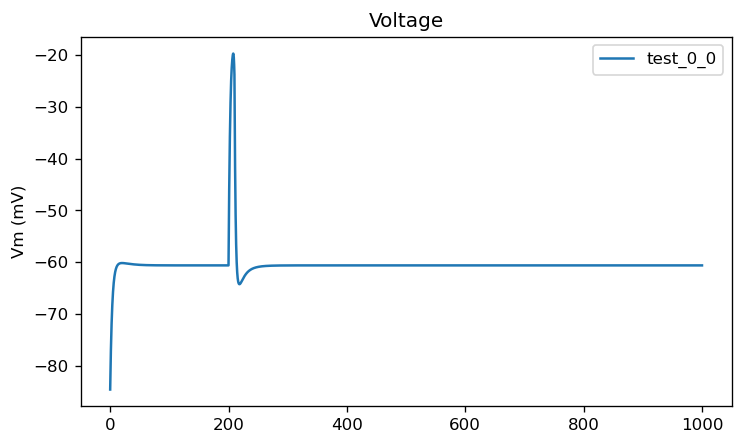

In [69]:
TS = 0.05
channels = {'Nav1p6':NaChannel,'leak':leak,"genericK":KChannel}
neuronDict = {'test': [Neuron(0,'test','excitatory',AISchannels=channels,AISbias=0)] }
spikerDict = {}
synapseDict = {}
simData = genSimData(neuronDict,spikerDict,synapseDict,TS)

def plotSimResult(simData,Nav1p6,leak):
    NavInd = simData['indexMaps']['neuronToChannelMap']['test'][0][0]['Nav1p6']
    leakInd = simData['indexMaps']['neuronToChannelMap']['test'][0][0]['leak']
    simData['conductance'][NavInd]  = Nav1p6
    simData['conductance'][leakInd] = leak
    runTime = 1000
    stimInfoSpikes,stimInfoCurrents = {},{}

    stimBiasCurrent(stimInfoCurrents,[0],-15,200,210,TS)

    simDataCpp = deepcopy(simData)
    simDataCpp["debugRecording"] = np.zeros_like(simDataCpp["current"])
    dataCpp = solveSystemCpp(simDataCpp,TS,runTime,samplingInterval=1,stimInfoSpikes=stimInfoSpikes,stimInfoCurrents=stimInfoCurrents,
                            recordingKeys =["spikerOutput","voltages"],singleThread=True)
    # dataCpp = solveSystemStandard(simDataCpp,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True)
    
    V = dataCpp["voltages"]
    tv = dataCpp["time"]
    fig,ax = plt.subplots(1,1,figsize=(7,4),sharex=True,dpi=120)
    # ax = np.atleast_1d(ax)
    ax.plot(tv,V,label = simData["neuronName"])
    ax.set_title("Voltage")
    ax.set_ylabel("Vm (mV)")
    ax.legend()  

plotSimResult(simData,10,0.3)

In [70]:
#NOTE: we can do strang splitting but we need to do the voltage for 2 steps and the gates for 1!
#NOTE: try something with MNIST 1d
#I had this idea for learning in neural networks, where we use a reward signal to tell a neuron to implement the STDP plasticity 
#For example neurons have STDP but they dont do the update unless the reward is active. Obviously the reward is delayed so the STDP signal has to accumulate
#There could be pro and anti reward signals (I'm thinking like with dopamine receptors that activate or inactivate K channels)
#With an anti rewards signal the neuron goes in the anti correlation direction (this idea is a little different, will ignore for now)
#I think in an ML context this sounds like reinforcment learning but it isnt. 
#I'm imagine a gradient being calculated continuously w.r.t some function in a real time or online or temporal system.
#If you get a positive reward you update in the direction of the gradient, otherwise keep recalculating a temporally local gradient. 
#My other idea was to use local connectivity in a neural STDP model as a way of introducing a spatial prior. 

In [71]:
import ipywidgets as widgets
from ipywidgets import interactive_output, VBox, HBox, Label, Layout

def plotSimResult(simData, **params): #gateValues
    gateIndMap = {key:i for i,key in enumerate(['vGate1','vGate2','CaGate','spikeGate'])}
    conductances,gateVals = {},{}

    for key,val in params.items():
        if "vg_" in key:
            gateVals[key] = val
        elif "cond_" in key:
            conductances[key] = val
        else:
            raise KeyError(f"Unknown key {key} in param dict")

    for channel,val in conductances.items():
        channel = channel.split("_")[1]
        ind = simData['indexMaps']['neuronToChannelMap']['test'][0][0][channel]
        simData['conductance'][ind] = val

    for gateData,val in gateVals.items():
        _,channel,gate,prop = gateData.split("_")
        channelInd = simData['indexMaps']['neuronToChannelMap']['test'][0][0][channel]
        gateInd = gateIndMap[gate]
        simData[prop][channelInd][gateInd] = val
        #rest of the logic later

    runTime = 250
    stimInfoSpikes,stimInfoCurrents = {},{}

    stimBiasCurrent(stimInfoCurrents,[0],-40,100,103,TS)

    simDataCpp = deepcopy(simData)
    simDataCpp["debugRecording"] = np.zeros_like(simDataCpp["current"])
    dataCpp = solveSystemCpp(simDataCpp,TS,runTime,samplingInterval=1,stimInfoSpikes=stimInfoSpikes,stimInfoCurrents=stimInfoCurrents,
                            recordingKeys =["spikerOutput","voltages"],singleThread=True)
    # dataCpp = solveSystemStandard(simDataCpp,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True)
    
    V = dataCpp["voltages"]
    tv = dataCpp["time"]
    fig,ax = plt.subplots(1,1,figsize=(7,4),sharex=True,dpi=120)
    # ax = np.atleast_1d(ax)
    ax.plot(tv,V,label = simData["neuronName"])
    ax.set_title("Voltage")
    ax.set_ylabel("Vm (mV)")
    ax.legend()  



def genUI_SingleNeuronSim(allParams,gateParameters):
    condSliderList = []
    for key,val in channels.items():
        c = val['conductance']
        cSlider = widgets.FloatSlider(value=c,  min=0.1*c,  max=10*c, step=0.1*c,  description=f'',continuous_update=False) #turn continuous update off to stop flashing
        sliderName = f"cond_{key}"
        allParams[sliderName] = cSlider 

        label = widgets.Label(value=f"{sliderName}:", layout=Layout(width='80px'))
        pairedWidget = HBox([label, cSlider], layout=Layout(justify_content='space-between'))
        condSliderList.append(pairedWidget)



    gateSliderList = []
    for keys in gateParameters:
        channel,gate,prop, valRange = keys
        sliderName = f"vg_{channel}_{gate}_{prop}"
        c = channels[channel]['gates'][gate][prop]
        gSlider = widgets.FloatSlider(value=c,  min=valRange[0],  max=valRange[1], step=(valRange[1]-valRange[0])/50,  description='',continuous_update=False)
        allParams[sliderName] = gSlider
        
        label = widgets.Label(value=f"{sliderName}:", layout=Layout(width='150px'))
        pairedWidget = HBox([label, gSlider], layout=Layout(justify_content='space-between'))
        gateSliderList.append(pairedWidget)


    # allSliders['simData'] = widgets.fixed(simData)
    widget_output = interactive_output(  plotSimResult,allParams)

    title_label = Label(
        value="Interactive AIS Action Potential Modulator",
        style={'font_weight': 'bold'})

    ui_container = VBox([
        title_label,
        HBox([VBox(condSliderList, layout=Layout(justify_content='center')),VBox(gateSliderList, layout=Layout(justify_content='center'))]),
        widget_output
    ], layout=Layout(align_items='center', padding='10px', border='1px solid #dcdfe5', border_radius='8px'))

    display(ui_container)

allParams = {'simData': widgets.fixed(simData)}
gateParameters =  [('Nav1p6','vGate2','minOpenness',(0,1)),
                   ('Nav1p6','vGate1','vHalf',(-80,50)),
                   ('genericK','vGate1','tau0',(1,30)),
                   ('genericK','vGate1','tau1',(1,30)),]

genUI_SingleNeuronSim(allParams,gateParameters)